In [1]:
from utils.library import *
from utils.download import *
from utils.metrics import split_temporal
from utils.stock_config import *
from models.arima import *
from models.xgboost import run_xgbooster
from utils.plots import plot_forecast

In [2]:
pretro_csv = 'data/petro.csv'

if not os.path.exists(pretro_csv):
    petr4_dataset = load_stock(STOCKS["petro"], "petro", force=True)
    petr4_dataset.head(10)

petr4_dataset = pd.read_csv(pretro_csv)

In [3]:
print(petr4_dataset.isna().sum())

date              0
petro_close       0
petro_high        0
petro_low         0
petro_open        0
petro_volume      0
ibovespa          0
vix               0
selic_daily       0
selic_goal        0
ipca              0
fx_usd            0
gdp               0
unemployment    535
dtype: int64


In [4]:
petr4_dataset.info()

<class 'pandas.DataFrame'>
RangeIndex: 3974 entries, 0 to 3973
Data columns (total 14 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   date          3974 non-null   str    
 1   petro_close   3974 non-null   float64
 2   petro_high    3974 non-null   float64
 3   petro_low     3974 non-null   float64
 4   petro_open    3974 non-null   float64
 5   petro_volume  3974 non-null   int64  
 6   ibovespa      3974 non-null   float64
 7   vix           3974 non-null   float64
 8   selic_daily   3974 non-null   float64
 9   selic_goal    3974 non-null   float64
 10  ipca          3974 non-null   float64
 11  fx_usd        3974 non-null   float64
 12  gdp           3974 non-null   float64
 13  unemployment  3439 non-null   float64
dtypes: float64(12), int64(1), str(1)
memory usage: 434.8 KB


## ARIMA

In [5]:
train_petro, test_petro = split_temporal(petr4_dataset)
res_petro = run_arima(train_petro, test_petro, "petro")

--- Identificando ordem do ARIMA para PETRO ---
Performing stepwise search to minimize aic
 ARIMA(2,2,2)(0,0,0)[0] intercept   : AIC=inf, Time=1.81 sec
 ARIMA(0,2,0)(0,0,0)[0] intercept   : AIC=-515.771, Time=0.14 sec
 ARIMA(1,2,0)(0,0,0)[0] intercept   : AIC=-1439.200, Time=0.08 sec
 ARIMA(0,2,1)(0,0,0)[0] intercept   : AIC=inf, Time=0.93 sec
 ARIMA(0,2,0)(0,0,0)[0]             : AIC=-517.754, Time=0.08 sec
 ARIMA(2,2,0)(0,0,0)[0] intercept   : AIC=-1869.916, Time=0.27 sec
 ARIMA(3,2,0)(0,0,0)[0] intercept   : AIC=-2080.443, Time=0.15 sec
 ARIMA(4,2,0)(0,0,0)[0] intercept   : AIC=-2225.261, Time=0.17 sec
 ARIMA(5,2,0)(0,0,0)[0] intercept   : AIC=-2279.631, Time=0.47 sec
 ARIMA(5,2,1)(0,0,0)[0] intercept   : AIC=-2695.759, Time=4.11 sec
 ARIMA(4,2,1)(0,0,0)[0] intercept   : AIC=-2687.980, Time=3.80 sec
 ARIMA(5,2,2)(0,0,0)[0] intercept   : AIC=-2669.127, Time=13.01 sec
 ARIMA(4,2,2)(0,0,0)[0] intercept   : AIC=inf, Time=8.39 sec
 ARIMA(5,2,1)(0,0,0)[0]             : AIC=inf, Time=1.54 

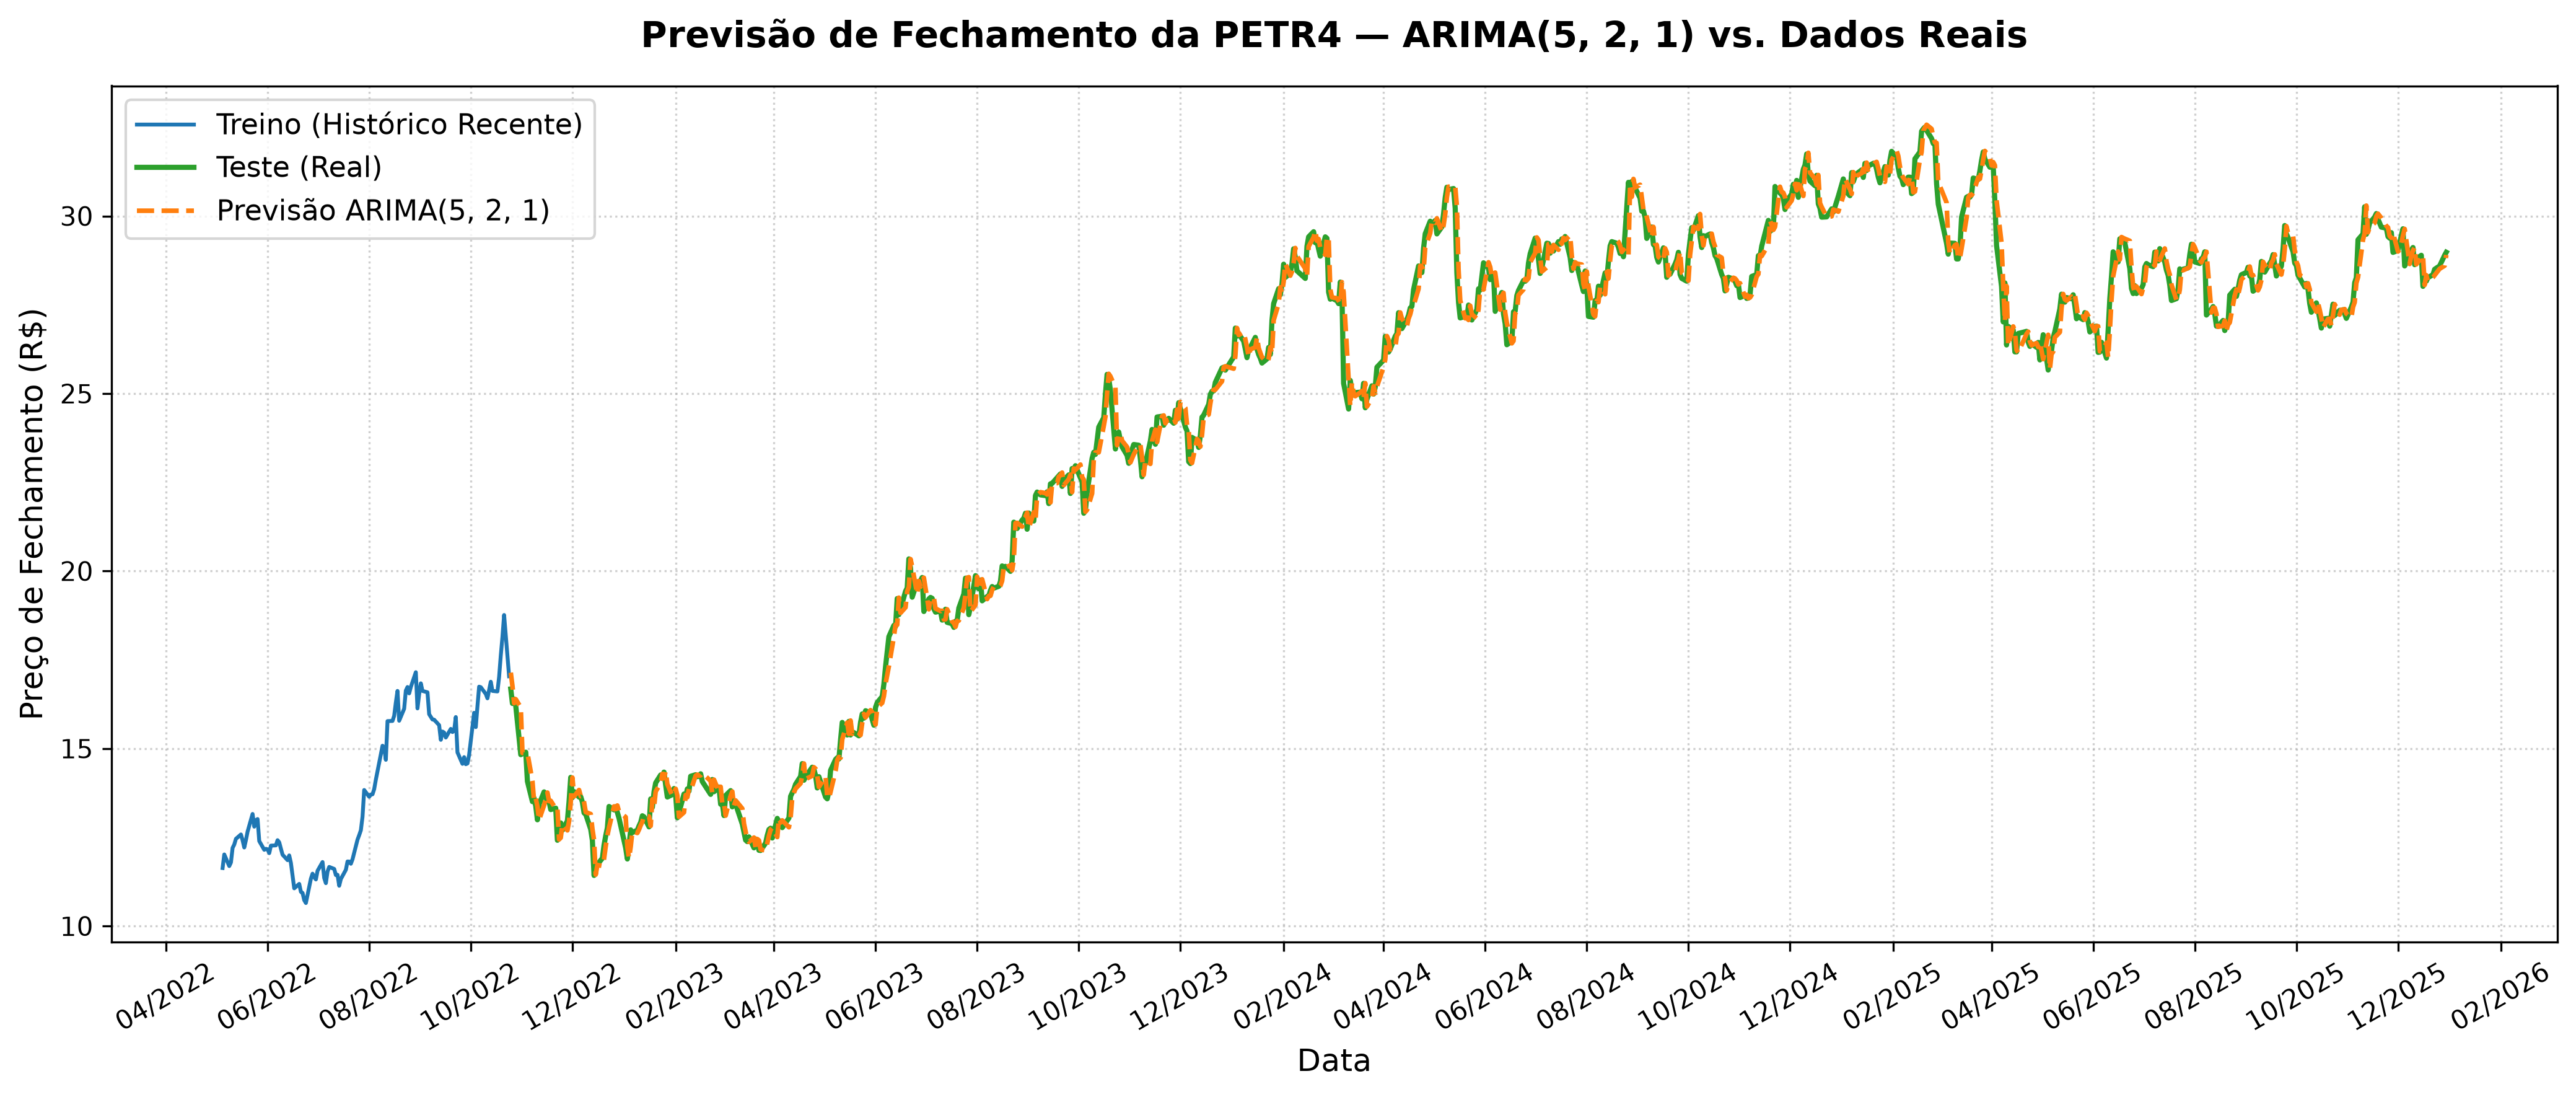

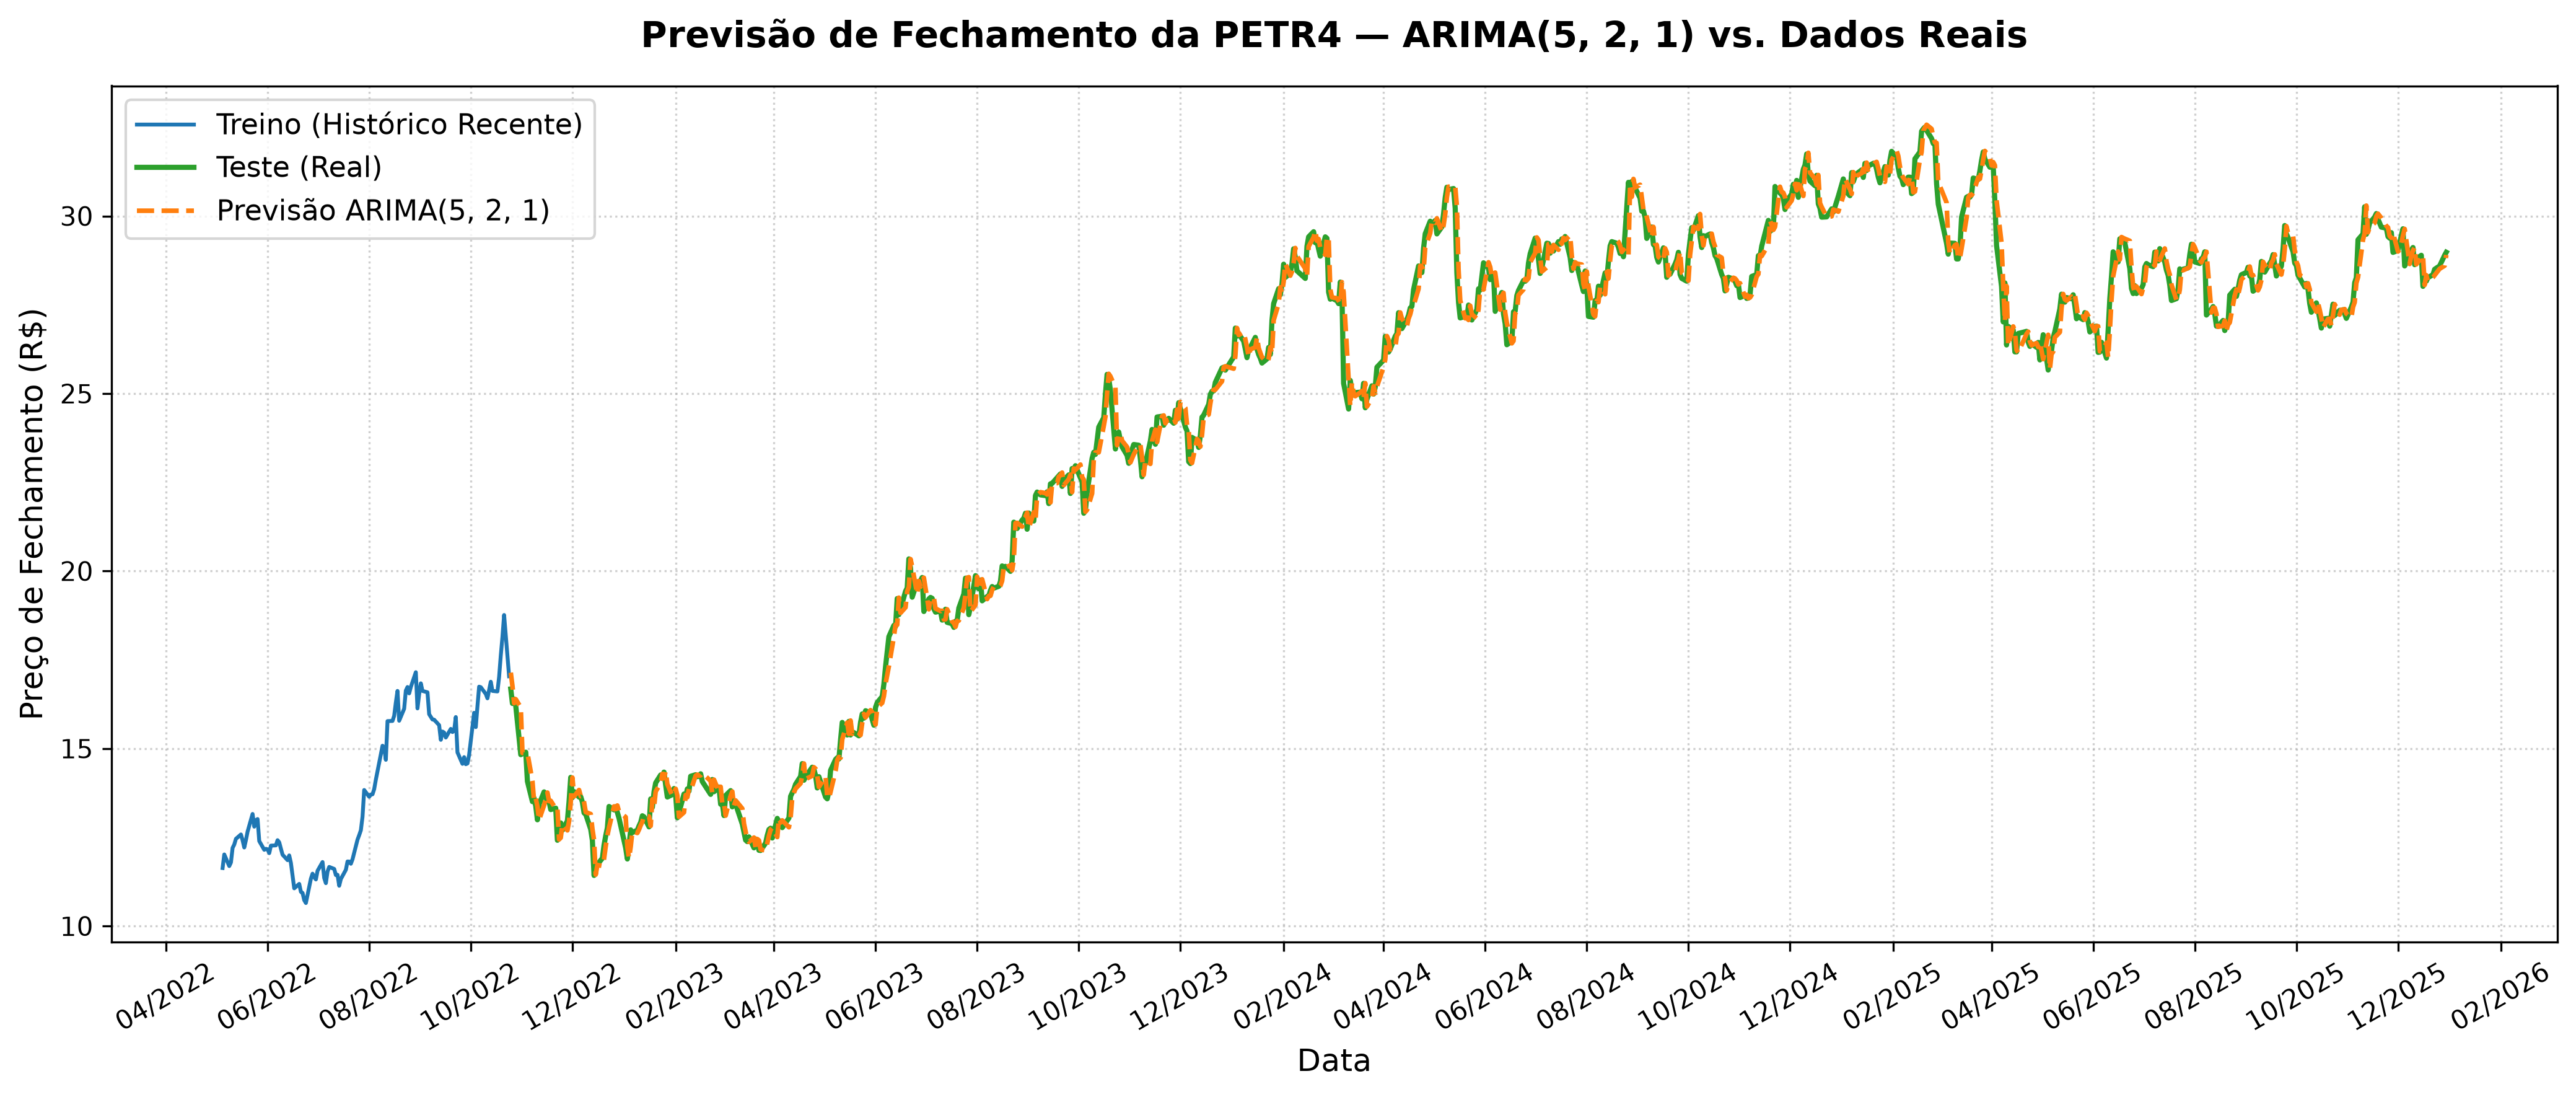

In [6]:
plot_forecast(
    train_petro, test_petro,
    predictions=res_petro["predictions"],
    stock_name="petro",
    model_name=f"ARIMA{res_petro['order']}",
    ticker_label="PETR4",
)

## XGBooster

--- XGBoost PETRO: 37 features, 2641 treino / 795 teste ---
Fitting 5 folds for each of 54 candidates, totalling 270 fits
Melhores hiperparâmetros: {'learning_rate': 0.1, 'max_depth': 3, 'n_estimators': 100, 'subsample': 0.8}
Melhor RMSE médio (validação): 1.0577
XGBoost petro          RMSE: 9.9352 | MAE: 8.7179 | MAPE: 32.13% | Acurácia direcional: 47.42%
Naive petro            RMSE: 0.4103 | MAE: 0.2960 | MAPE: 1.30% | Acurácia direcional: n/a
p-valor (teste binomial, acurácia direcional): 0.1560


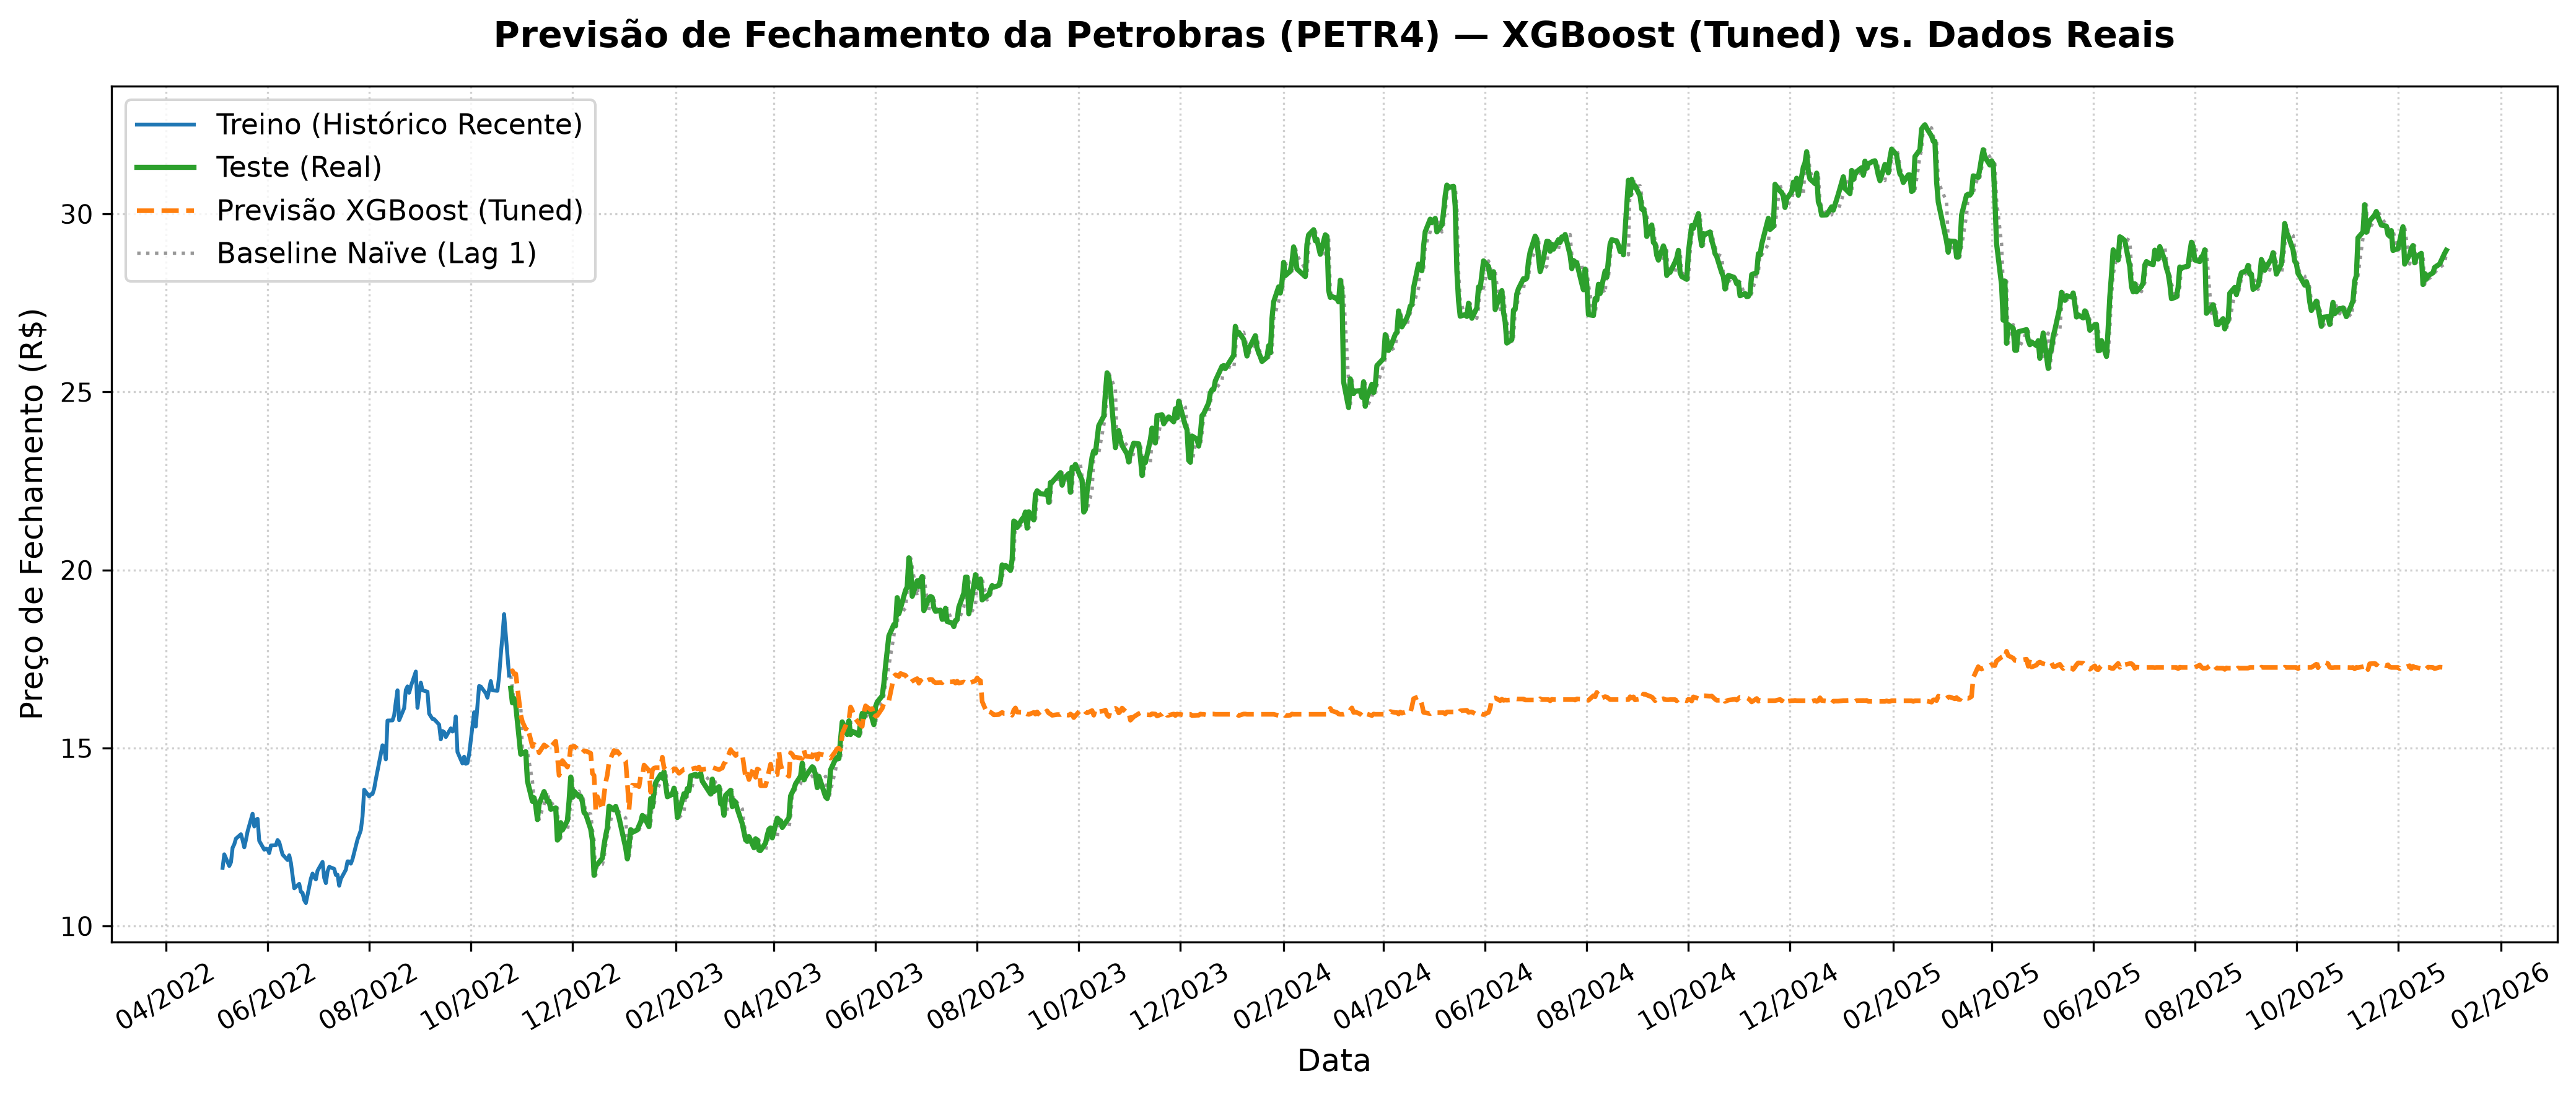

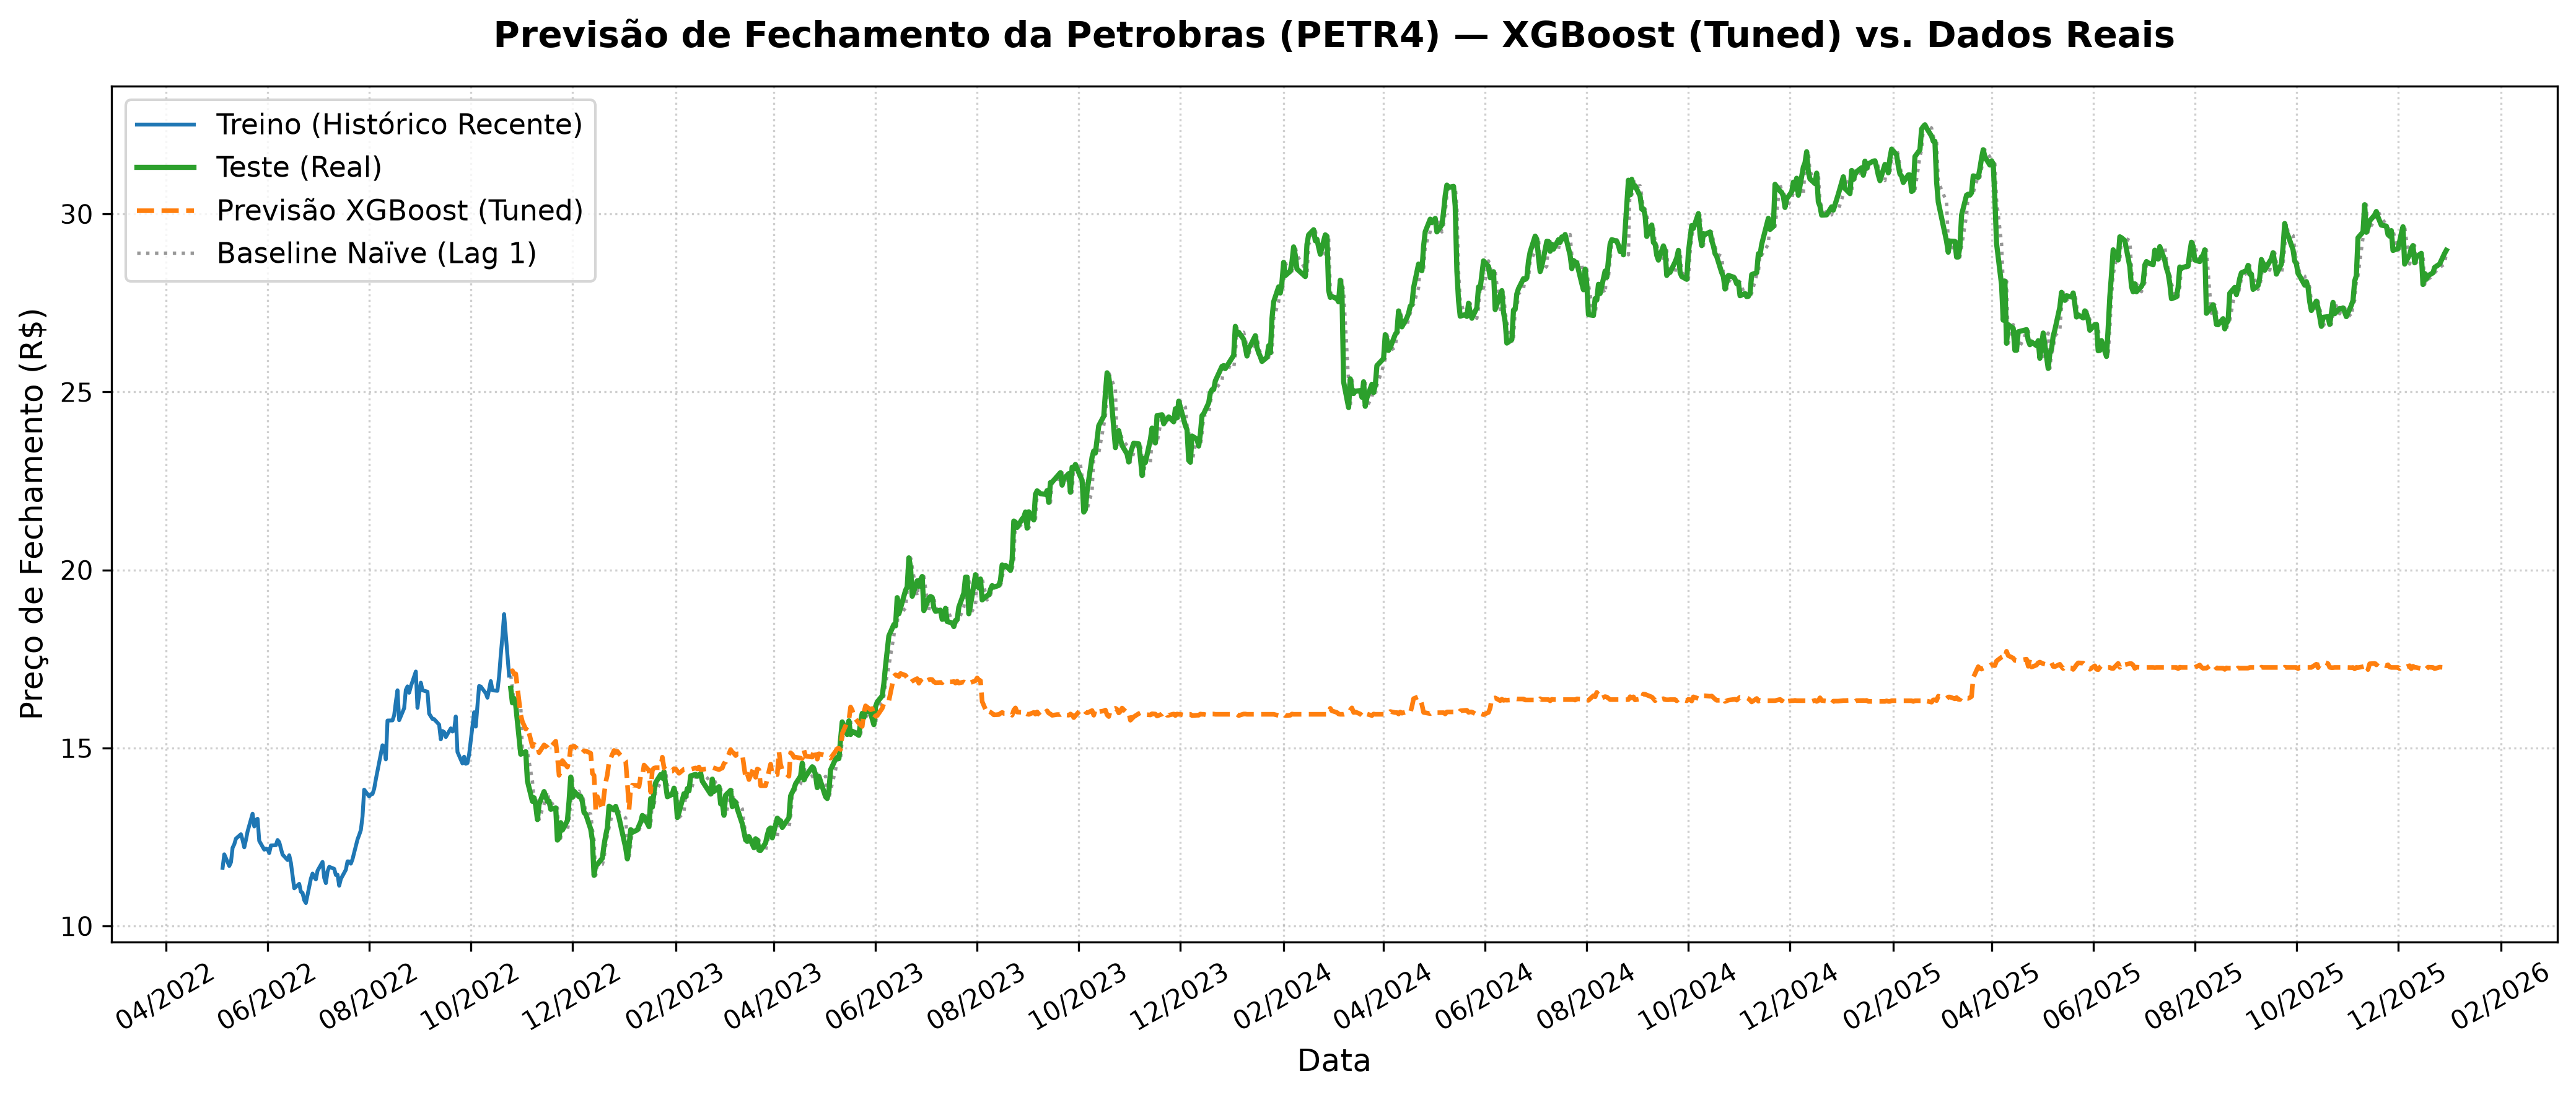

In [7]:
res = run_xgbooster(train_petro, test_petro, "petro")
plot_forecast(
    train_petro, test_petro,
    predictions=res["predictions"],
    stock_name="petro",
    model_name="XGBoost (Tuned)",
    ticker_label="PETR4",
    company_name="Petrobras",
    baseline=res["ontem"],        # baseline naive (preço de ontem)
)

In [ ]:
res_lstm = run_lstm(train_petro, test_petro, "petro", max_epochs=10)
plot_forecast(train_petro, test_petro, res_lstm["predictions"], "petro",
              model_name="LSTM (Tuned)", ticker_label="PETR3",
              company_name="Petrobras", baseline=res_lstm["ontem"])